# Task 4: Classification with Logistic Regression

**Objective:** Build a binary classifier using Logistic Regression.

**Dataset:** Breast Cancer Wisconsin Dataset (included in Scikit-learn).

**Tools:** Scikit-learn, Pandas, NumPy, and Matplotlib.

This notebook covers data preparation, feature standardization, model training, evaluation, threshold tuning, and the sigmoid function.

In [1]:
# Step-1: Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    classification_report,
    f1_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Step-2: Load the Breast Cancer Wisconsin Dataset

dataset = load_breast_cancer()

X = pd.DataFrame(dataset.data, columns=dataset.feature_names)

# In this task, 1 means malignant and 0 means benign.
y = pd.Series((dataset.target == 0).astype(int), name="target")

# Create a readable dataset preview.
df = X.copy()
df["diagnosis"] = np.where(y == 1, "malignant", "benign")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["diagnosis"].value_counts())
print("\nDataset preview:")
display(df[["mean radius", "mean texture", "mean perimeter", "mean area", "mean smoothness", "diagnosis"]].head())

Dataset loaded successfully!
Dataset shape: (569, 31)

Class distribution:
diagnosis
benign       357
malignant    212
Name: count, dtype: int64

Dataset preview:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,malignant
1,20.57,17.77,132.90,1326.0,0.08474,malignant
2,19.69,21.25,130.00,1203.0,0.10960,malignant
3,11.42,20.38,77.58,386.1,0.14250,malignant
4,20.29,14.34,135.10,1297.0,0.10030,malignant


In [3]:
# Step-3: Split Data into Training and Testing Sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("\nTraining class counts:")
print(y_train.value_counts().rename(index={0: "Benign", 1: "Malignant"}))
print("\nTesting class counts:")
print(y_test.value_counts().rename(index={0: "Benign", 1: "Malignant"}))

Training data: (455, 30)
Testing data: (114, 30)

Training class counts:
target
Benign       285
Malignant    170
Name: count, dtype: int64

Testing class counts:
target
Benign       72
Malignant    42
Name: count, dtype: int64


In [4]:
# Step-4: Standardize the Features

# Keep a small validation set from the training data for threshold selection.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Fit the scaler only on the fitting data to avoid data leakage.
scaler_tune = StandardScaler()
X_fit_scaled = scaler_tune.fit_transform(X_fit)
X_val_scaled = scaler_tune.transform(X_val)

print("Features standardized successfully!")
print("Fitting data:", X_fit_scaled.shape)
print("Validation data:", X_val_scaled.shape)

Features standardized successfully!
Fitting data: (364, 30)
Validation data: (91, 30)


In [5]:
# Step-5: Train a Logistic Regression Model for Threshold Tuning

model_tune = LogisticRegression(max_iter=1000, random_state=42)
model_tune.fit(X_fit_scaled, y_fit)

validation_probabilities = model_tune.predict_proba(X_val_scaled)[:, 1]

print("Validation model trained successfully!")

Validation model trained successfully!


In [6]:
# Step-6: Tune the Classification Threshold

threshold_values = np.arange(0.20, 0.81, 0.05)
threshold_results = []

for threshold in threshold_values:
    validation_predictions = (validation_probabilities >= threshold).astype(int)
    threshold_results.append({
        "Threshold": round(float(threshold), 2),
        "Precision": precision_score(y_val, validation_predictions, zero_division=0),
        "Recall": recall_score(y_val, validation_predictions, zero_division=0),
        "F1 Score": f1_score(y_val, validation_predictions, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)
best_row = threshold_df.loc[threshold_df["F1 Score"].idxmax()]
best_threshold = float(best_row["Threshold"])

print("Threshold comparison:")
display(threshold_df.round(3))
print("Selected threshold:", best_threshold)
print("The threshold is selected using validation data, not the test data.")

Threshold comparison:


,Threshold,Precision,Recall,F1 Score
0,0.20,0.825,0.971,0.892
1,0.25,0.868,0.971,0.917
2,0.30,0.943,0.971,0.957
3,0.35,0.943,0.971,0.957
4,0.40,0.943,0.971,0.957
5,0.45,0.943,0.971,0.957
6,0.50,0.943,0.971,0.957
7,0.55,0.943,0.971,0.957
8,0.60,0.943,0.971,0.957
9,0.65,1.000,0.971,0.985


Selected threshold: 0.65
The threshold is selected using validation data, not the test data.


In [7]:
# Step-7: Train the Final Logistic Regression Model

# Refit the scaler and model using the complete training set.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

print("Final Logistic Regression Model Trained Successfully!")

Final Logistic Regression Model Trained Successfully!


In [8]:
# Step-8: Make Predictions and Evaluate the Model

y_prob = model.predict_proba(X_test_scaled)[:, 1]
y_pred = (y_prob >= best_threshold).astype(int)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print("Selected threshold:", round(best_threshold, 2))
print("Confusion Matrix:")
print(cm)
print("\nPrecision (Malignant):", round(precision, 4))
print("Recall (Malignant):", round(recall, 4))
print("ROC-AUC Score:", round(roc_auc, 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Benign", "Malignant"], zero_division=0))

Selected threshold: 0.65
Confusion Matrix:
[[72  0]
 [ 4 38]]

Precision (Malignant): 1.0
Recall (Malignant): 0.9048
ROC-AUC Score: 0.996

Classification Report:
              precision    recall  f1-score   support

      Benign       0.95      1.00      0.97        72
   Malignant       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



## Understanding the Evaluation Results

- **Confusion matrix:** Shows correct and incorrect predictions. The rows represent actual classes and the columns represent predicted classes.
- **Precision:** Of the cases predicted as malignant, how many were actually malignant.
- **Recall:** Of all actual malignant cases, how many the model correctly identified.
- **ROC-AUC:** Measures how well the model separates the two classes across different thresholds. A value closer to 1 indicates stronger separation.

## Understanding the Sigmoid Function

The sigmoid function is \(\sigma(z) = \frac{1}{1 + e^{-z}}\). It converts any real-valued model output into a probability between 0 and 1. Logistic Regression uses this probability to classify a case. A threshold decides the class; this notebook selects its threshold using validation data and the F1 score.

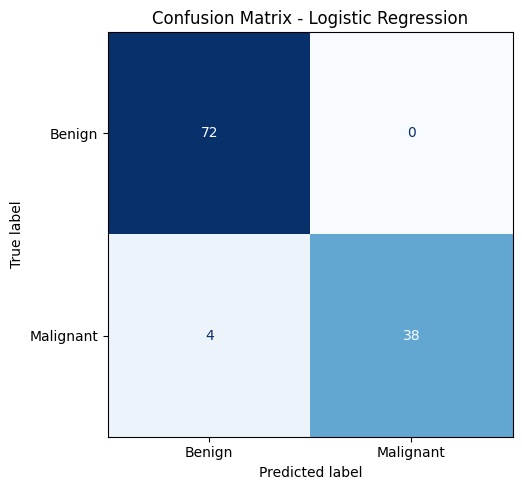

In [9]:
# Step-9: Plot the Confusion Matrix

fig, ax = plt.subplots(figsize=(6, 5))
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)
display.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

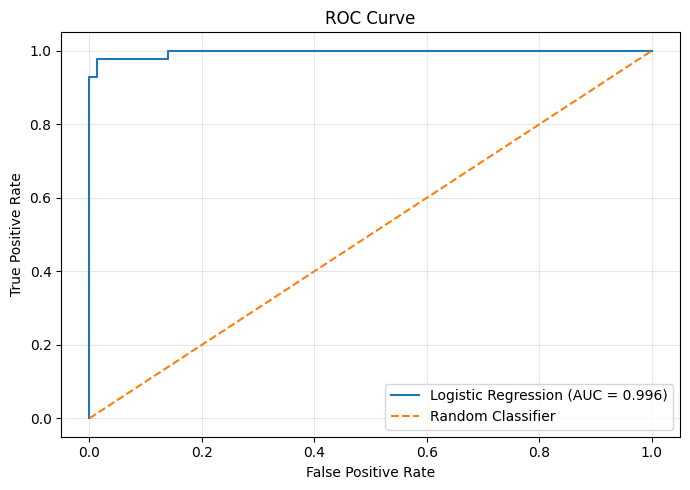

In [10]:
# Step-10: Plot the ROC Curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

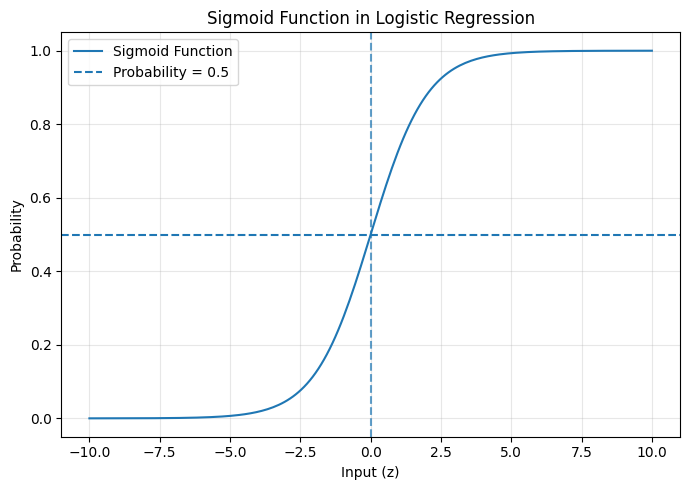

The sigmoid function converts model output into a probability between 0 and 1.


In [11]:
# Step-11: Visualize the Sigmoid Function

z = np.linspace(-10, 10, 200)
sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(7, 5))
plt.plot(z, sigmoid, label="Sigmoid Function")
plt.axhline(0.5, linestyle="--", label="Probability = 0.5")
plt.axvline(0, linestyle="--", alpha=0.7)
plt.xlabel("Input (z)")
plt.ylabel("Probability")
plt.title("Sigmoid Function in Logistic Regression")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("The sigmoid function converts model output into a probability between 0 and 1.")

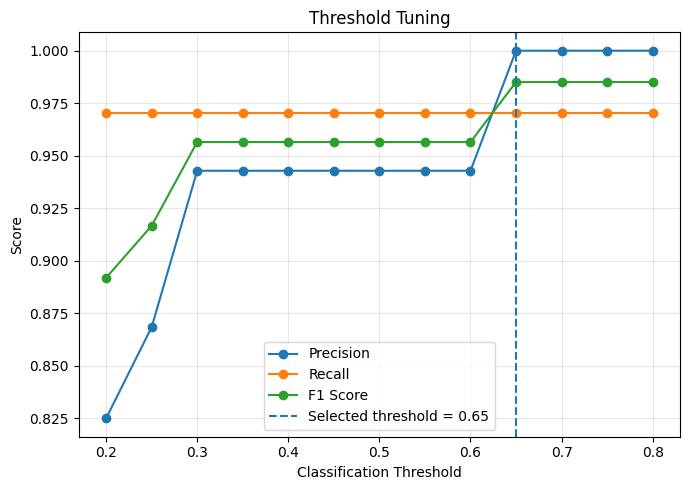

In [12]:
# Step-12: Plot Precision, Recall, and F1 Score for Different Thresholds

plt.figure(figsize=(7, 5))
plt.plot(threshold_df["Threshold"], threshold_df["Precision"], marker="o", label="Precision")
plt.plot(threshold_df["Threshold"], threshold_df["Recall"], marker="o", label="Recall")
plt.plot(threshold_df["Threshold"], threshold_df["F1 Score"], marker="o", label="F1 Score")
plt.axvline(best_threshold, linestyle="--", label=f"Selected threshold = {best_threshold:.2f}")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Threshold Tuning")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Conclusion

Logistic Regression was used to classify breast cancer cases as malignant or benign. The dataset was split into training and testing sets, and features were standardized before training. The model was evaluated using a confusion matrix, precision, recall, and ROC-AUC. A threshold was selected using validation data, and the sigmoid function was visualized to understand how logistic regression converts model output into probabilities.

**Note:** The positive class is malignant (1), so precision and recall focus on correctly identifying malignant cases.